<a href="https://colab.research.google.com/github/ben-blake/umkc-deep-learning/blob/main/hw5-learning/HW5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Homework 5 - Self-Supervised Learning**

In this homework, we will introduce four different autoencoders for the task of anomaly detection.

**Name:** Ben Blake

**Student ID:** 14387365

# Set up the environment


## Package installation

In [1]:
# Training progress bar
!pip install -q qqdm
!pip install -q tqdm

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


## Untar data

hw5_data contains 2 files
```
hw5_data/
├── trainingset.npy
├── testingset.npy
```

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
!unzip -q -o "/content/drive/My Drive/UMKC/Fall 2026/Deep Learning/HW5/hw5_data.zip" -d /content/

# Import packages

In [4]:
import numpy as np
import random
import torch
import torchvision

from torch.utils.data import DataLoader
from torch.utils.data import (DataLoader, RandomSampler, SequentialSampler,
                              TensorDataset)
import torchvision.transforms as transforms

from torch import nn
import torch.nn.functional as F
from torch.autograd import Variable
import torchvision.models as models

from torch.optim import Adam, AdamW

from sklearn.cluster import MiniBatchKMeans
from scipy.cluster.vq import vq, kmeans

from qqdm import qqdm, format_str
import tqdm
import pandas as pd

import matplotlib.pyplot as plt

import pdb  # use pdb.set_trace() to set breakpoints for debugging




# Loading data

In [5]:

train = np.load('/content/hw5_data/trainingset.npy', allow_pickle=True)
test = np.load('/content/hw5_data/testingset.npy', allow_pickle=True)

print(train.shape)
print(test.shape)

(850, 64, 64, 3)
(150, 64, 64, 3)


## Random seed
Set the random seed to a certain value for reproducibility.

In [6]:
def same_seeds(seed):
    # Python built-in random module
    random.seed(seed)
    # Numpy
    np.random.seed(seed)
    # Torch
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True

same_seeds(12345678)

# Autoencoder

# Models & loss (16pts)

In [7]:
class fcn_autoencoder(nn.Module):
    def __init__(self):
        super(fcn_autoencoder, self).__init__()
        self.encoder = nn.Sequential(
            nn.Linear(64*64*3, 128),
            nn.ReLU(True),
            nn.Linear(128, 64),
            nn.ReLU(True),
            nn.Linear(64, 12),
            nn.ReLU(True),
            nn.Linear(12, 3)   ) # (1pt) Todo: Use a linear layer with proper # of input_channels and # of output_channels
            # 12 in from the previous layer, 3 out because the decoder starts with Linear(3, 12).
            # so every 12,288-pixel image gets squeezed into a 3-dim code. no ReLU after it, so the code can go negative

        self.decoder = nn.Sequential(
            nn.Linear(3, 12),
            nn.ReLU(True),
            nn.Linear(12, 64),
            nn.ReLU(True),
            nn.Linear(64, 128),
            nn.ReLU(True),
            nn.Linear(128, 64 * 64 * 3),
            nn.Tanh()  ) # (1pt) Todo: Use a Tanh as an activation layer
            # Tanh keeps the output in [-1, 1], the same range CustomTensorDataset maps the pixels to

    def forward(self, x):
        x = self.encoder(x)
        x = self.decoder(x)
        return x


# maybe it can be smaller
class conv_autoencoder(nn.Module):
    def __init__(self):
        super(conv_autoencoder, self).__init__()
        self.encoder = nn.Sequential(
            nn.Conv2d(3, 12, 4, stride=2, padding=1)    , # (1pt) Todo: Use a conv layer with proper # of input_channels and # of output_channels with kernel_size=4, stride=2 and padding=1
            # RGB in, 12 out to match the next Conv2d(12, 24). k=4, s=2, p=1 halves H and W exactly: (64 + 2 - 4)/2 + 1 = 32
            nn.ReLU()    , # (1pt) Todo: Use a ReLu as an activation layer
            nn.Conv2d(12, 24, 4, stride=2, padding=1),
            nn.ReLU(),
			      nn.Conv2d(24, 48, 4, stride=2, padding=1),
            nn.ReLU(),
            # so the encoder goes 3x64x64 -> 12x32x32 -> 24x16x16 -> 48x8x8
        )
        self.decoder = nn.Sequential(
			      nn.ConvTranspose2d(48, 24, 4, stride=2, padding=1)    , # (1pt) Todo: Use a transpose conv layer with proper # of input_channels and # of output_channels with kernel_size=4, stride=2 and padding=1
            # mirror of the last encoder conv: 48 in from the code, 24 out for the next ConvTranspose2d(24, 12).
            # same k/s/p doubles H and W: (8 - 1)*2 - 2 + 4 = 16
            nn.ReLU(),
			      nn.ConvTranspose2d(24, 12, 4, stride=2, padding=1),
            nn.ReLU(),
            nn.ConvTranspose2d(12, 3, 4, stride=2, padding=1)    , # (1pt) Todo: Use a transpose conv layer with proper # of input_channels and # of output_channels with kernel_size=4, stride=2 and padding=1
            # back to 3 channels at 64x64, then Tanh puts it in [-1, 1]
            nn.Tanh(),
        )

    def forward(self, x):
        x = self.encoder(x)
        x = self.decoder(x)
        return x


class VAE(nn.Module):
    def __init__(self):
        super(VAE, self).__init__()
        self.encoder = nn.Sequential(
            nn.Conv2d(3, 12, 4, stride=2, padding=1)    , # (1pt) Todo: Use a conv layer with proper # of input_channels and # of output_channels with kernel_size=4, stride=2 and padding=1
            # same first layer as the conv autoencoder: 3x64x64 -> 12x32x32
            nn.ReLU(),
            nn.Conv2d(12, 24, 4, stride=2, padding=1),
            nn.ReLU(),
        )
        self.enc_out_1 = nn.Sequential(
            nn.Conv2d(24, 48, 4, stride=2, padding=1)    , # (1pt) Todo: Use a conv layer with proper # of input_channels and # of output_channels with kernel_size=4, stride=2 and padding=1
            # mu head. takes the shared 24x16x16 features to 48x8x8, which is what the decoder's ConvTranspose2d(48, 24) expects
            nn.ReLU(),
        )
        self.enc_out_2 = nn.Sequential(
            nn.Conv2d(24, 48, 4, stride=2, padding=1)    , # (1pt) Todo: Use a conv layer with proper # of input_channels and # of output_channels with kernel_size=4, stride=2 and padding=1
            # logvar head. same shape as mu since reparametrize combines them elementwise (mu + eps * std)
            nn.ReLU(),
        )
        self.decoder = nn.Sequential(
			      nn.ConvTranspose2d(48, 24, 4, stride=2, padding=1),
            nn.ReLU(),
			      nn.ConvTranspose2d(24, 12, 4, stride=2, padding=1)    , # (1pt) Todo: Use a transpose conv layer with proper # of input_channels and # of output_channels with kernel_size=4, stride=2 and padding=1
            # 24 in from the layer above, 12 out for the final ConvTranspose2d(12, 3). 16x16 -> 32x32
            nn.ReLU(),
            nn.ConvTranspose2d(12, 3, 4, stride=2, padding=1),
            nn.Tanh(),
        )

    def encode(self, x):
        h1 = self.encoder(x)
        return self.enc_out_1(h1), self.enc_out_2(h1)

    def reparametrize(self, mu, logvar):
        std = logvar.mul(0.5).exp_()
        if torch.cuda.is_available():
            eps = torch.cuda.FloatTensor(std.size()).normal_()
        else:
            eps = torch.FloatTensor(std.size()).normal_()
        eps = Variable(eps)
        return eps.mul(std).add_(mu)

    def decode(self, z):
        return self.decoder(z)

    def forward(self, x):
        mu, logvar = self.encode(x)
        z = self.reparametrize(mu, logvar)
        return self.decode(z), mu, logvar


def loss_vae(recon_x, x, mu, logvar, criterion):
    """
    recon_x: generating images
    x: origin images
    mu: latent mean
    logvar: latent log variance
    """
    mse = criterion(recon_x, x)  # mse loss
    KLD_element = mu.pow(2).add_(logvar.exp()).mul_(-1).add_(1).add_(logvar)
    KLD = torch.sum(KLD_element).mul_(-0.5)
    return mse + KLD


class Resnet(nn.Module):
    def __init__(self, fc_hidden1=1024, fc_hidden2=768, drop_p=0.3, CNN_embed_dim=256):
        super(Resnet, self).__init__()

        self.fc_hidden1, self.fc_hidden2, self.CNN_embed_dim = fc_hidden1, fc_hidden2, CNN_embed_dim

        # CNN architechtures
        self.ch1, self.ch2, self.ch3, self.ch4 = 16, 32, 64, 128
        self.k1, self.k2, self.k3, self.k4 = (5, 5), (3, 3), (3, 3), (3, 3)      # 2d kernal size
        self.s1, self.s2, self.s3, self.s4 = (2, 2), (2, 2), (2, 2), (2, 2)      # 2d strides
        self.pd1, self.pd2, self.pd3, self.pd4 = (0, 0), (0, 0), (0, 0), (0, 0)  # 2d padding

        # encoding components
        resnet = models.resnet18(pretrained=False)
        modules = list(resnet.children())[:-1]      # delete the last fc layer.
        self.resnet = nn.Sequential(*modules)
        self.fc1 = nn.Linear(resnet.fc.in_features, self.fc_hidden1)
        self.bn1 = nn.BatchNorm1d(self.fc_hidden1, momentum=0.01) # (1pt) Todo: Use a batchnorm1d layer with proper input_size and momentum=0.01
        # normalizes fc1's 1024 outputs. dropped the template's trailing comma: `x = layer,` makes a tuple, which isn't callable
        self.fc2 = nn.Linear(self.fc_hidden1, self.fc_hidden2)
        self.bn2 = nn.BatchNorm1d(self.fc_hidden2, momentum=0.01)

        self.fc3_mu = nn.Linear(self.fc_hidden2, self.CNN_embed_dim)      # output = CNN embedding latent variables

        # Sampling vector
        self.fc4 = nn.Linear(self.CNN_embed_dim, self.fc_hidden2)
        self.fc_bn4 = nn.BatchNorm1d(self.fc_hidden2)
        self.fc5 = nn.Linear(self.fc_hidden2, 64 * 4 * 4)
        self.fc_bn5 = nn.BatchNorm1d(64 * 4 * 4) # (1pt) Todo: Use a batchnorm1d layer with proper input_size
        # matches fc5's 1024 outputs, before decode() reshapes them to 64x4x4. same trailing-comma fix as bn1
        self.relu = nn.ReLU(inplace=True)

        # Decoder
        self.convTrans6 = nn.Sequential(
            nn.ConvTranspose2d(in_channels=64, out_channels=32, kernel_size=self.k4, stride=self.s4,
                               padding=self.pd4),
            nn.BatchNorm2d(32, momentum=0.01),
            nn.ReLU(inplace=True),
        )
        self.convTrans7 = nn.Sequential(
            nn.ConvTranspose2d(in_channels=32, out_channels=8, kernel_size=self.k3, stride=self.s3,
                               padding=self.pd3),
            nn.BatchNorm2d(8, momentum=0.01),
            nn.ReLU(inplace=True),
        )

        self.convTrans8 = nn.Sequential(
            nn.ConvTranspose2d(in_channels=8, out_channels=3, kernel_size=self.k2, stride=self.s2,
                               padding=self.pd2),
            nn.BatchNorm2d(3, momentum=0.01),
            nn.Sigmoid()    # y = (y1, y2, y3) \in [0 ,1]^3
        )


    def encode(self, x):
        x = self.resnet(x)  # ResNet
        x = x.view(x.size(0), -1)  # (1pt)Todo :Flatten output of conv
        # resnet18 minus its fc ends in adaptive avgpool, so this is (N, 512, 1, 1) -> (N, 512) for fc1

        # FC layers
        if x.shape[0] > 1:
            x = self.bn1(self.fc1(x))
        else:
            x = self.fc1(x)
        x = self.relu(x)
        if x.shape[0] > 1:
            x = self.bn2(self.fc2(x))
        else:
            x = self.fc2(x)
        x = self.relu(x)
        x = self.fc3_mu(x)
        return x

    def decode(self, z):
        if z.shape[0] > 1:
            x = self.relu(self.fc_bn4(self.fc4(z)))
            x = self.relu(self.fc_bn5(self.fc5(x))).view(-1, 64, 4, 4)
        else:
            x = self.relu(self.fc4(z))
            x = self.relu(self.fc5(x)).view(-1, 64, 4, 4)
        x = self.convTrans6(x)
        x = self.convTrans7(x)
        x = self.convTrans8(x)
        x = F.interpolate(x, size=(64, 64), mode='bilinear', align_corners=True) # (1pt)Todo : Use a bi-linear interpolation to size of (64,64) with align_corners=True
        # the three no-padding transpose convs go 4 -> 9 -> 19 -> 39, so this resizes 39x39 up to the 64x64 input size
        return x

    def forward(self, x):
        z = self.encode(x)
        x_reconst = self.decode(z)

        return x_reconst


# Dataset module

Module for obtaining and processing data. The transform function here normalizes image's pixels from [0, 255] to [-1.0, 1.0].


In [8]:
class CustomTensorDataset(TensorDataset):
    """TensorDataset with support of transforms.
    """
    def __init__(self, tensors):
        self.tensors = tensors
        if tensors.shape[-1] == 3:
            # self.tensors = tensors.permute(0, 3, 1, 2)
            self.tensors = tensors.permute(0, 3, 1, 2)

        # You may add some transforms below
        self.transform = transforms.Compose([
                            transforms.Lambda(lambda x: x.to(torch.float32)),
                            transforms.Lambda(lambda x: 2. * x/255. - 1.),
                            # transforms.Normalize([0.5, 0.5, 0.5], [0.5, 0.5, 0.5]),
                            ])

    def __getitem__(self, index):
        x = self.tensors[index]

        if self.transform:
            # mapping images to [-1.0, 1.0]
            x = self.transform(x)

        return x

    def __len__(self):
        return len(self.tensors)

# Training

## Initialize
- hyperparameters
- dataloader
- model
- optimizer & loss


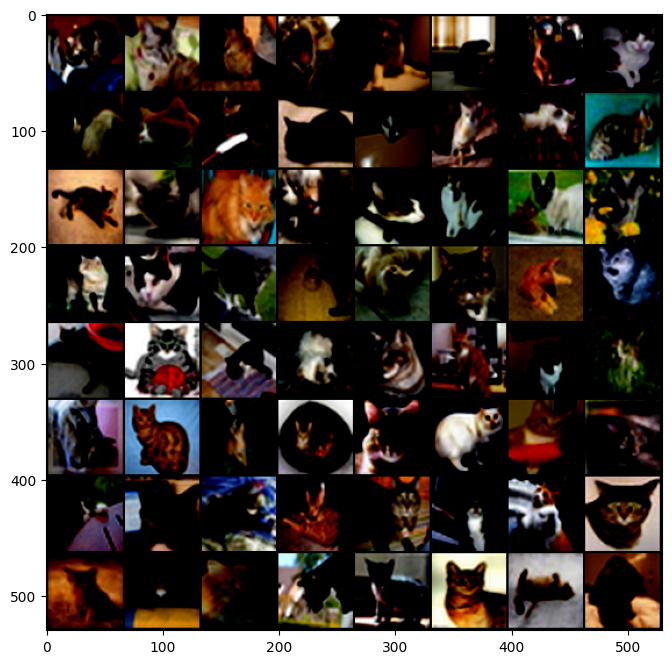

In [10]:
# Training hyperparameters
num_epochs = 20
batch_size = 1024
learning_rate = 1e-6

# Build training dataloader
x = torch.from_numpy(train)
train_dataset = CustomTensorDataset(x)

train_sampler = RandomSampler(train_dataset)
train_dataloader = DataLoader(train_dataset, sampler=train_sampler, batch_size=batch_size)

images = [train_dataset[i] for i in range(64)]
grid_img = torchvision.utils.make_grid(images, nrow=8)
plt.figure(figsize=(8,8))
plt.imshow(grid_img.permute(1, 2, 0))
plt.show()

# Resnet

In [11]:
# Model
model_type = 'resnet'   # selecting a model type from {'cnn', 'fcn', 'vae', 'resnet'}
model_classes = {'resnet': Resnet(), 'fcn':fcn_autoencoder(), 'cnn':conv_autoencoder(), 'vae':VAE(), }
model = model_classes[model_type].cuda()

# Loss and optimizer
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(
    model.parameters(), lr=learning_rate)

/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:207: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:222: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=None`.
  warnings.warn(msg)


## Training loop

In [13]:

best_loss = np.inf
model.train()

qqdm_train = qqdm(range(num_epochs), desc=format_str('bold', 'Description'))
# template had format_str('bold'), but qqdm's format_str(style, s) needs the string too, so it raised a TypeError
for epoch in qqdm_train:
    tot_loss = list()
    for data in train_dataloader:

        # ===================loading=====================
        if model_type in ['cnn', 'vae', 'resnet']:
            img = data.float().cuda()
        elif model_type in ['fcn']:
            img = data.float().cuda()
            img = img.view(img.shape[0], -1)

        # ===================forward=====================
        output = model(img)
        if model_type in ['vae']:
            loss = loss_vae(output[0], img, output[1], output[2], criterion)
        else:
            loss = criterion(output, img)

        tot_loss.append(loss.item())
        # ===================backward====================
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
    # ===================save_best====================
    mean_loss = np.mean(tot_loss)
    if mean_loss < best_loss:
        best_loss = mean_loss
        torch.save(model, 'best_model_{}.pt'.format(model_type))
    # ===================log========================
    qqdm_train.set_infos({
      'epoch': f'{epoch + 1:.0f}/{num_epochs:.0f}',
      'loss': f'{mean_loss:.4f}',
    })
    # ===================save_last========================
    torch.save(model, 'last_model_{}.pt'.format(model_type))




 Iters    Elapsed Time      Speed                                               
 0/20           -             -                                                 
Description   0.0% |                                                           | Iters    Elapsed Time      Speed    epoch   loss                               
 1/20   00:00:02<00:00:54  0.35it/s  1/20   0.6184                              
Description   5.0% |██                                                         | Iters    Elapsed Time      Speed    epoch   loss                               
 2/20   00:00:03<00:00:31  0.57it/s  2/20   0.6182                              
Description  10.0% |█████                                                      | Iters    Elapsed Time      Speed    epoch   loss                               
 3/20   00:00:04<00:00:24  0.70it/s  3/20   0.6181                              
Description  15.0% |████████                                                   | Iters    Elapsed Time      Spee

# FCN_autoencoder

In [14]:
# Model
model_type = 'fcn'   # selecting a model type from {'cnn', 'fcn', 'vae', 'resnet'}
model_classes = {'resnet': Resnet(), 'fcn':fcn_autoencoder(), 'cnn':conv_autoencoder(), 'vae':VAE(), }
model = model_classes[model_type].cuda()

# Loss and optimizer
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(
    model.parameters(), lr=learning_rate)

## Training loop

In [15]:

best_loss = np.inf
model.train()

qqdm_train = qqdm(range(num_epochs), desc=format_str('bold', 'Description'))
# same format_str fix as the ResNet loop
for epoch in qqdm_train:
    tot_loss = list()
    for data in train_dataloader:

        # ===================loading=====================
        if model_type in ['cnn', 'vae', 'resnet']:
            img = data.float().cuda()
        elif model_type in ['fcn']:
            img = data.float().cuda()
            img = img.view(img.shape[0], -1)

        # ===================forward=====================
        output = model(img)
        if model_type in ['vae']:
            loss = loss_vae(output[0], img, output[1], output[2], criterion)
        else:
            loss = criterion(output, img)

        tot_loss.append(loss.item())
        # ===================backward====================
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
    # ===================save_best====================
    mean_loss = np.mean(tot_loss)
    if mean_loss < best_loss:
        best_loss = mean_loss
        torch.save(model, 'best_model_{}.pt'.format(model_type))
    # ===================log========================
    qqdm_train.set_infos({
      'epoch': f'{epoch + 1:.0f}/{num_epochs:.0f}',
      'loss': f'{mean_loss:.4f}',
    })
    # ===================save_last========================
    torch.save(model, 'last_model_{}.pt'.format(model_type))



 Iters    Elapsed Time      Speed                                               
 0/20           -             -                                                 
Description   0.0% |                                                           | Iters    Elapsed Time      Speed    epoch   loss                               
 1/20   00:00:00<00:00:04  4.16it/s  1/20   0.2716                              
Description   5.0% |██                                                         | Iters    Elapsed Time      Speed    epoch   loss                               
 3/20   00:00:00<00:00:03  5.41it/s  3/20   0.2716                              
Description  15.0% |████████                                                   | Iters    Elapsed Time      Speed    epoch   loss                               
 5/20   00:00:00<00:00:02  5.95it/s  5/20   0.2716                              
Description  25.0% |██████████████                                             | Iters    Elapsed Time      Spee

# Conv_Autoencoder

In [16]:
# Model
model_type = 'cnn'   # selecting a model type from {'cnn', 'fcn', 'vae', 'resnet'}
model_classes = {'resnet': Resnet(), 'fcn':fcn_autoencoder(), 'cnn':conv_autoencoder(), 'vae':VAE(), }
model = model_classes[model_type].cuda()

# Loss and optimizer
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(
    model.parameters(), lr=learning_rate)

## Training loop

In [17]:

best_loss = np.inf
model.train()

qqdm_train = qqdm(range(num_epochs), desc=format_str('bold', 'Description'))
# same format_str fix as the ResNet loop
for epoch in qqdm_train:
    tot_loss = list()
    for data in train_dataloader:

        # ===================loading=====================
        if model_type in ['cnn', 'vae', 'resnet']:
            img = data.float().cuda()
        elif model_type in ['fcn']:
            img = data.float().cuda()
            img = img.view(img.shape[0], -1)

        # ===================forward=====================
        output = model(img)
        if model_type in ['vae']:
            loss = loss_vae(output[0], img, output[1], output[2], criterion)
        else:
            loss = criterion(output, img)

        tot_loss.append(loss.item())
        # ===================backward====================
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
    # ===================save_best====================
    mean_loss = np.mean(tot_loss)
    if mean_loss < best_loss:
        best_loss = mean_loss
        torch.save(model, 'best_model_{}.pt'.format(model_type))
    # ===================log========================
    qqdm_train.set_infos({
      'epoch': f'{epoch + 1:.0f}/{num_epochs:.0f}',
      'loss': f'{mean_loss:.4f}',
    })
    # ===================save_last========================
    torch.save(model, 'last_model_{}.pt'.format(model_type))



 Iters    Elapsed Time      Speed                                               
 0/20           -             -                                                 
Description   0.0% |                                                           | Iters    Elapsed Time      Speed    epoch   loss                               
 2/20   00:00:00<00:00:02  6.98it/s  2/20   0.2676                              
Description  10.0% |█████                                                      | Iters    Elapsed Time      Speed    epoch   loss                               
 4/20   00:00:00<00:00:02  7.14it/s  4/20   0.2676                              
Description  20.0% |███████████                                                | Iters    Elapsed Time      Speed    epoch   loss                               
 6/20   00:00:00<00:00:01  7.31it/s  6/20   0.2676                              
Description  30.0% |█████████████████                                          | Iters    Elapsed Time      Spee

# VAE

In [18]:
# Model
model_type = 'vae'   # selecting a model type from {'cnn', 'fcn', 'vae', 'resnet'}
model_classes = {'resnet': Resnet(), 'fcn':fcn_autoencoder(), 'cnn':conv_autoencoder(), 'vae':VAE(), }
model = model_classes[model_type].cuda()

# Loss and optimizer
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(
    model.parameters(), lr=learning_rate)

## Training loop

In [19]:

best_loss = np.inf
model.train()

qqdm_train = qqdm(range(num_epochs), desc=format_str('bold', 'Description'))
# same format_str fix as the ResNet loop
for epoch in qqdm_train:
    tot_loss = list()
    for data in train_dataloader:

        # ===================loading=====================
        if model_type in ['cnn', 'vae', 'resnet']:
            img = data.float().cuda()
        elif model_type in ['fcn']:
            img = data.float().cuda()
            img = img.view(img.shape[0], -1)

        # ===================forward=====================
        output = model(img)
        if model_type in ['vae']:
            loss = loss_vae(output[0], img, output[1], output[2], criterion)
        else:
            loss = criterion(output, img)

        tot_loss.append(loss.item())
        # ===================backward====================
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
    # ===================save_best====================
    mean_loss = np.mean(tot_loss)
    if mean_loss < best_loss:
        best_loss = mean_loss
        torch.save(model, 'best_model_{}.pt'.format(model_type))
    # ===================log========================
    qqdm_train.set_infos({
      'epoch': f'{epoch + 1:.0f}/{num_epochs:.0f}',
      'loss': f'{mean_loss:.4f}',
    })
    # ===================save_last========================
    torch.save(model, 'last_model_{}.pt'.format(model_type))



 Iters    Elapsed Time      Speed                                               
 0/20           -             -                                                 
Description   0.0% |                                                           |/tmp/ipykernel_1938/915188130.py:101: UserWarning: The torch.cuda.*DtypeTensor constructors are no longer recommended. It's best to use methods such as torch.tensor(data, dtype=*, device='cuda') to create tensors. (Triggered internally at /__w/pytorch/pytorch/torch/csrc/tensor/python_tensor.cpp:78.)
  eps = torch.cuda.FloatTensor(std.size()).normal_()
 Iters    Elapsed Time      Speed    epoch    loss                              
 1/20   00:00:00<00:00:04  4.16it/s  1/20   6710.3105                           
Description   5.0% |██                                                         | Iters    Elapsed Time      Speed    epoch    loss                              
 2/20   00:00:00<00:00:04  4.19it/s  2/20   6703.8789                           


# **Summary**

I trained all four autoencoders with the template's settings (20 epochs, batch size 1024, Adam at lr 1e-6, MSE loss) on a T4. Everything runs end to end, but with these hyperparameters the models slowly learn to reconstruct the images.

**Data**

`trainingset.npy` is 850 images and `testingset.npy` is 150, all 64x64 RGB stored as uint8. `CustomTensorDataset` permutes them to channels-first and maps the pixels to [-1, 1]. Since 850 is less than the batch size of 1024, the whole training set is one batch, so each "epoch" is a single optimizer step and 20 epochs is just 20 steps. The test set gets loaded but nothing in the template uses it.

**Models**

| model | parameters | shape of the code |
|---|---|---|
| FCN | 3,176,419 | 3 numbers (12,288 → 128 → 64 → 12 → 3) |
| CNN | 47,355 | 48x8x8 (3x64x64 → 12x32x32 → 24x16x16 → 48x8x8) |
| VAE | 65,835 | mu and logvar, each 48x8x8, from two conv heads on the shared 24x16x16 features |
| ResNet | 13,698,969 | 256 (resnet18 trunk → 1024 → 768 → 256) |

The CNN and VAE decoders mirror their encoders with k=4, s=2, p=1 transpose convs, so every layer exactly doubles the size and they land back on 64x64. The ResNet decoder's transpose convs don't have padding and go 4 → 9 → 19 → 39, so the bilinear interpolation TODO resizes 39x39 to 64x64. In the template the two ResNet batchnorm TODOs had a trailing comma (`self.bn1 = ????? ,`), which would have stored a tuple instead of a layer, so I left the comma out.

**Results**

Mean training loss (one batch) after the first and last epoch:

| model | epoch 1 | epoch 20 | time |
|---|---|---|---|
| FCN | 0.2716 | 0.2716 | ~3 s |
| CNN | 0.2676 | 0.2676 | ~3 s |
| VAE | 6710.31 | 6589.14 | ~5 s |
| ResNet | 0.6184 | 0.6161 | ~24 s |

For reference, outputting all zeros gets an MSE of 0.2671 on this data, and outputting the mean training image gets 0.2548. So the FCN and CNN are about where you'd be with a blank image. Their changes are past the fourth decimal at lr 1e-6, so the log doesn't move. The VAE and ResNet losses go down every epoch, but from much higher starting points, for different reasons:

- **VAE:** `loss_vae` adds a *summed* KL term to a *mean* MSE. KL is summed over 850 images x 3072 latent values, while MSE is averaged per pixel, so KL is basically the entire loss. After training the MSE part is 0.274 and the KL part is about 6,583. So the drop from 6710 to 6589 is the latents getting pulled toward N(0, 1), not better reconstructions.
- **ResNet:** the decoder ends in a Sigmoid, so it outputs [0, 1], but the targets are in [-1, 1]. It can't produce any negative pixel, which on its own puts a floor of about 0.160 MSE on it. It also starts out further away (0.618), since BatchNorm and Sigmoid push the untrained output to around 0.5 everywhere.

**What I'd change**

None of these are TODO lines, so I left them as the template has them:

- lr 1e-6 with only 20 steps is the main reason nothing trains. Something like lr 1e-3 with a batch size of 64-128 (14-7 steps per epoch) would give each model 140-280 real updates over the same 20 epochs.
- Average the VAE's KL term (or scale it down) so it's on the same scale as the MSE.
- Either drop the ResNet decoder's Sigmoid for a Tanh, or rescale its targets to [0, 1].
- The notebook stops after training. Actual anomaly detection would reconstruct the test set and use each image's reconstruction error as its anomaly score.

**Changes outside the TODOs**

- Replaced the `path to/` placeholders in the loading cell, and added cells to mount Google Drive and unzip `hw5_data.zip` into `/content`.
- In all four training loops, changed `format_str('bold')` to `format_str('bold', 'Description')`. The current `qqdm`'s `format_str` takes the style and the string, so the original line raised `TypeError: format_str() missing 1 required positional argument: 's'` before training started.

#**AI Use Disclosure**

Anthropic Claude Code was utilized on this assignment. Its contributions were: assistance with the explanatory comments next to updated TODO items and the summary. I personally modified, reviewed, and ran the final notebook.

#**Documentation Referenced**

**Data loading:**
- numpy.load - https://numpy.org/doc/stable/reference/generated/numpy.load.html
- torch.utils.data (TensorDataset, DataLoader, RandomSampler) - https://pytorch.org/docs/stable/data.html
- torchvision.transforms - https://pytorch.org/vision/stable/transforms.html
- PyTorch reproducibility - https://pytorch.org/docs/stable/notes/randomness.html

**Model:**
- nn.Linear - https://pytorch.org/docs/stable/generated/torch.nn.Linear.html
- nn.Conv2d - https://pytorch.org/docs/stable/generated/torch.nn.Conv2d.html
- nn.ConvTranspose2d - https://pytorch.org/docs/stable/generated/torch.nn.ConvTranspose2d.html
- nn.BatchNorm1d - https://pytorch.org/docs/stable/generated/torch.nn.BatchNorm1d.html
- nn.ReLU - https://pytorch.org/docs/stable/generated/torch.nn.ReLU.html
- nn.Tanh - https://pytorch.org/docs/stable/generated/torch.nn.Tanh.html
- torch.nn.functional.interpolate - https://pytorch.org/docs/stable/generated/torch.nn.functional.interpolate.html
- Tensor.view - https://pytorch.org/docs/stable/generated/torch.Tensor.view.html
- torchvision.models.resnet18 - https://pytorch.org/vision/stable/models/generated/torchvision.models.resnet18.html
- Auto-Encoding Variational Bayes - https://arxiv.org/abs/1312.6114
- Deep Residual Learning for Image Recognition - https://arxiv.org/abs/1512.03385

**Loss & training:**
- nn.MSELoss - https://pytorch.org/docs/stable/generated/torch.nn.MSELoss.html
- torch.optim.Adam - https://pytorch.org/docs/stable/generated/torch.optim.Adam.html
- qqdm - https://github.com/KinglittleQ/qqdm